--- BLOQUE 1 ---
Valores nulos:
 latencia_ms    0
grupo          0
dtype: int64

Tipos de datos:
 latencia_ms    float64
grupo           object
dtype: object

Resumen Estadístico (Datos Depurados):
                     Media     Mediana  Desv_Estd     Varianza  Asimetría  \
grupo                                                                       
Microservicios  124.614395  113.968825  48.204082  2323.633513   0.769817   
Monolito        123.199647  117.011831  43.529150  1894.786920   0.616269   

                Curtosis  
grupo                     
Microservicios -0.093737  
Monolito       -0.158652  


/tmp/ipykernel_1202/470948256.py:48: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_clean = df.groupby('grupo', group_keys=False).apply(remover_outliers)


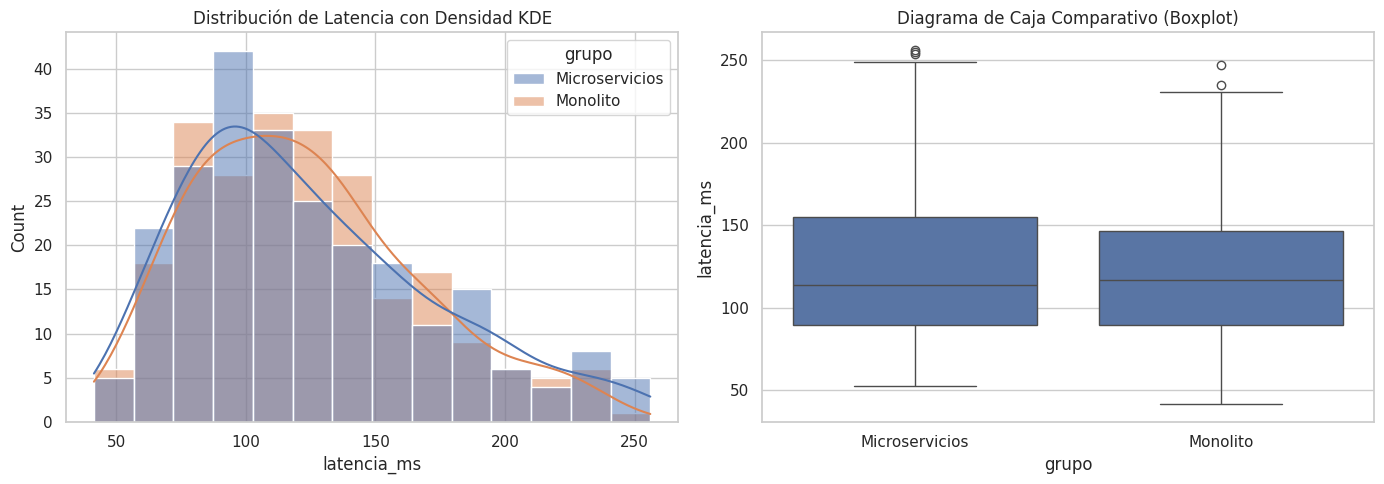


--- BLOQUE 2 ---


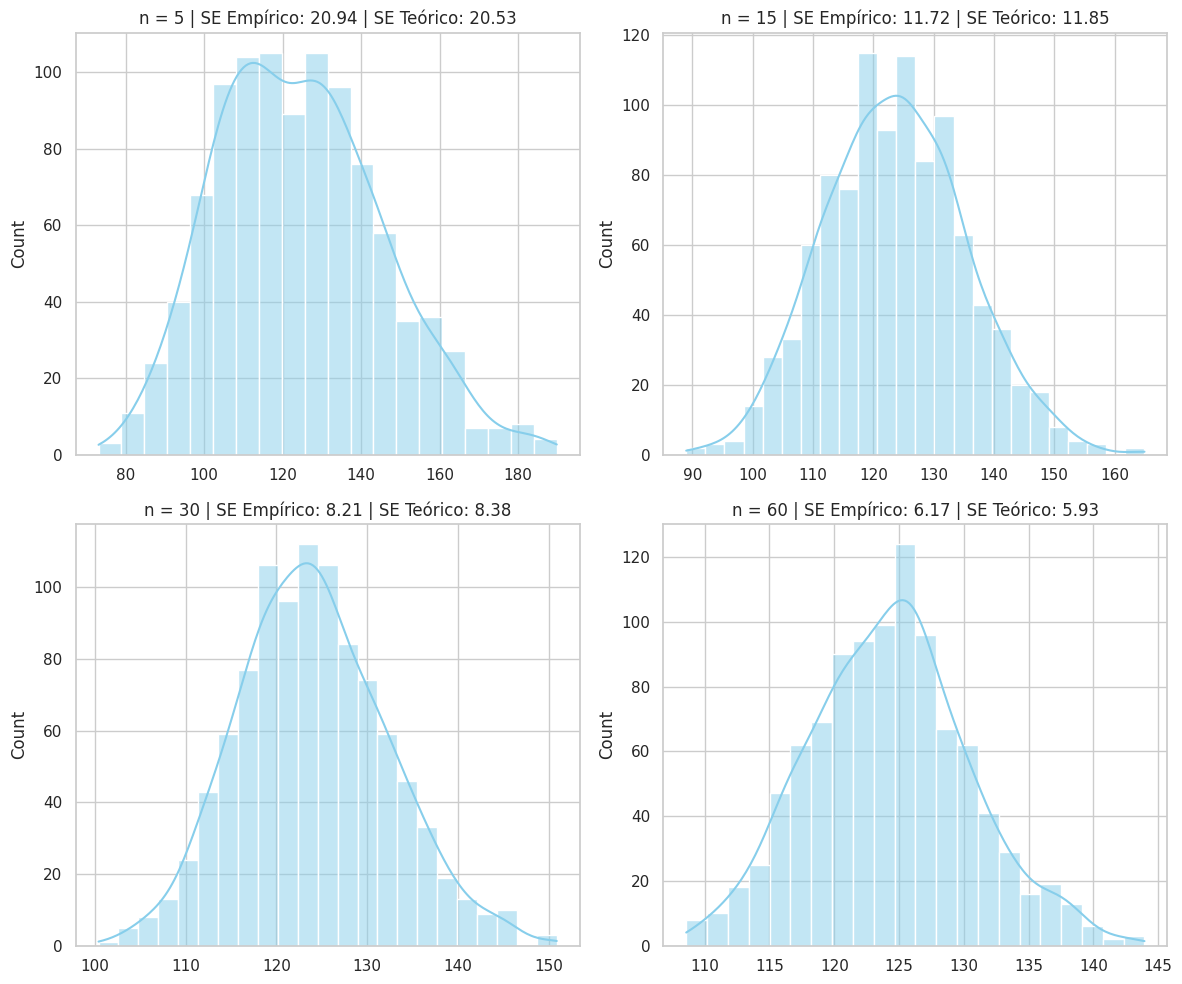


--- BLOQUE 3 ---
IC General 90%: (120.48, 127.35)
IC General 95%: (119.82, 128.00)
IC General 99%: (118.53, 129.29)

Prueba de Levene p-value: 0.1754
IC 95% para la Diferencia de Medias (Monolito - Microservicios): (-9.60, 6.77)

--- BLOQUE 4 ---
Estadístico t: -0.3384
p-value: 7.3522e-01
Veredicto: NO se rechaza la hipótesis nula (H0). No hay evidencia suficiente de diferencia.


In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Crear la carpeta 'data' automáticamente si no existe
os.makedirs('data', exist_ok=True)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# ==========================================
# CARGA DEL DATASET (Caso A)
# ==========================================
np.random.seed(42)
n = 250

lat_monolito = np.random.gamma(shape=2.5, scale=35, size=n) + 40
lat_microserv = np.random.gamma(shape=2.2, scale=40, size=n) + 45

df = pd.DataFrame({
    'latencia_ms': np.concatenate([lat_monolito, lat_microserv]),
    'grupo': ['Monolito'] * n + ['Microservicios'] * n
})

# Guardar en la carpeta data
df.to_csv('data/dataset_caso_a.csv', index=False)

# ==========================================
# BLOQUE 1: ESTADÍSTICA DESCRIPTIVA Y LIMPIEZA
# ==========================================
print("--- BLOQUE 1 ---")
# 1. Verificación de tipos y ausentes
print("Valores nulos:\n", df.isnull().sum())
print("\nTipos de datos:\n", df.dtypes)

# 2. Detección y remoción de outliers vía IQR por grupo
def remover_outliers(data):
    Q1 = data['latencia_ms'].quantile(0.25)
    Q3 = data['latencia_ms'].quantile(0.75)
    IQR = Q3 - Q1
    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR
    return data[(data['latencia_ms'] >= limite_inferior) & (data['latencia_ms'] <= limite_superior)]

df_clean = df.groupby('grupo', group_keys=False).apply(remover_outliers)

# Guardar versión depurada en data
df_clean.to_csv('data/dataset_caso_a_depurado.csv', index=False)

# 3. Métricas descriptivas por grupo
def resumen_estadistico(data):
    stats_df = data.groupby('grupo')['latencia_ms'].agg(
        Media='mean',
        Mediana='median',
        Desv_Estd='std',
        Varianza='var'
    )
    stats_df['Asimetría'] = data.groupby('grupo')['latencia_ms'].apply(lambda x: stats.skew(x))
    stats_df['Curtosis'] = data.groupby('grupo')['latencia_ms'].apply(lambda x: stats.kurtosis(x))
    return stats_df

print("\nResumen Estadístico (Datos Depurados):")
print(resumen_estadistico(df_clean))

# 4. Gráficos KDE y Boxplots
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(data=df_clean, x='latencia_ms', hue='grupo', kde=True, ax=axes[0])
axes[0].set_title('Distribución de Latencia con Densidad KDE')

sns.boxplot(data=df_clean, x='grupo', y='latencia_ms', ax=axes[1])
axes[1].set_title('Diagrama de Caja Comparativo (Boxplot)')
plt.tight_layout()
plt.show()

# ==========================================
# BLOQUE 2: TEOREMA CENTRAL DEL LÍMITE (TCL)
# ==========================================
print("\n--- BLOQUE 2 ---")
poblacion = df_clean['latencia_ms'].values
s_poblacional = np.std(poblacion, ddof=1)
k = 1000
tamanios = [5, 15, 30, 60]

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

for i, size in enumerate(tamanios):
    medias_muestrales = [np.mean(np.random.choice(poblacion, size=size, replace=True)) for _ in range(k)]
    se_empirico = np.std(medias_muestrales, ddof=1)
    se_teorico = s_poblacional / np.sqrt(size)

    sns.histplot(medias_muestrales, kde=True, ax=axes[i], color='skyblue')
    axes[i].set_title(f'n = {size} | SE Empírico: {se_empirico:.2f} | SE Teórico: {se_teorico:.2f}')

plt.tight_layout()
plt.show()

# ==========================================
# BLOQUE 3: INTERVALOS DE CONFIANZA
# ==========================================
print("\n--- BLOQUE 3 ---")
# 1. IC para la media general
n_total = len(poblacion)
media_gen = np.mean(poblacion)
se_gen = stats.sem(poblacion)

for conf in [0.90, 0.95, 0.99]:
    ic = stats.norm.interval(conf, loc=media_gen, scale=se_gen)
    print(f"IC General {int(conf*100)}%: ({ic[0]:.2f}, {ic[1]:.2f})")

# 2. IC para la diferencia de medias (Monolito vs Microservicios)
g_mono = df_clean[df_clean['grupo'] == 'Monolito']['latencia_ms']
g_micro = df_clean[df_clean['grupo'] == 'Microservicios']['latencia_ms']

# Test de Levene
stat_lev, p_lev = stats.levene(g_mono, g_micro)
print(f"\nPrueba de Levene p-value: {p_lev:.4f}")

equal_var = p_lev > 0.05
diff = g_mono.mean() - g_micro.mean()
se_diff = np.sqrt(g_mono.var()/len(g_mono) + g_micro.var()/len(g_micro))

ic_diff = stats.norm.interval(0.95, loc=diff, scale=se_diff)
print(f"IC 95% para la Diferencia de Medias (Monolito - Microservicios): ({ic_diff[0]:.2f}, {ic_diff[1]:.2f})")

# ==========================================
# BLOQUE 4: PRUEBA DE HIPÓTESIS
# ==========================================
print("\n--- BLOQUE 4 ---")
alpha = 0.05
t_stat, p_val = stats.ttest_ind(g_mono, g_micro, equal_var=equal_var)

print(f"Estadístico t: {t_stat:.4f}")
print(f"p-value: {p_val:.4e}")

if p_val < alpha:
    print("Veredicto: Se RECHAZA la hipótesis nula (H0). Existe una diferencia estadísticamente significativa.")
else:
    print("Veredicto: NO se rechaza la hipótesis nula (H0). No hay evidencia suficiente de diferencia.")